In [ ]:
import pandas as pd
import cv2
import numpy as np
from PIL import Image, ImageEnhance
from skimage.transform import resize
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import StratifiedGroupKFold
import os, re, hashlib, json
import seaborn as sns

### **Task 1: Exploratory Data Analysis**

In [ ]:
# --- PATH ROOT ---
DATA_ROOT = "../data/kahikatea/data"          # folder containing ve_positive/ and ve_negative/
CLASSES   = ["ve_positive", "ve_negative"]
CLASSES   = ["ve_positive", "ve_negative"]
LABEL_MAP = {c: int(c == "ve_positive") for c in CLASSES}
FIG_DIR   = "../figures/Task1-2"
os.makedirs(FIG_DIR, exist_ok=True)

palette = {"ve_positive": "#2e7d32", "ve_negative": "#b71c1c"}
sns.set_theme(style="whitegrid", font_scale=1.0)

#### Introduction and dataset organisation

Scanning every image : For each file I record: file size, MD5 hash (exact-duplicate check),
perceptual hash (near-duplicate check), format/colour mode, width/height/
aspect ratio, mean/std brightness, RGB channel means, a sharpness proxy
(Laplacian variance), and over/under-exposure fractions. Any file that fails
to open or decode is logged separately rather than crashing the scan.

In [49]:
records = []
errors = []

for cls in CLASSES:
    folder = os.path.join(DATA_ROOT, cls)
    for f in sorted(os.listdir(folder)):
        path = os.path.join(folder, f)
        rec = {"class": cls, "filename": f, "path": path}
        try:
            rec["filesize_kb"] = os.path.getsize(path) / 1024

            with open(path, "rb") as fh:
                data = fh.read()
            rec["md5"] = hashlib.md5(data).hexdigest()

            img = Image.open(path)
            img.verify()            # raises if corrupted
            img = Image.open(path)  # re-open after verify()

            rec["format"] = img.format
            rec["mode"] = img.mode
            w, h = img.size
            rec["width"], rec["height"] = w, h
            rec["aspect_ratio"] = w / h
            rec["n_channels"] = len(img.getbands())
            rec["phash"] = str(imagehash.phash(img))

            arr = np.array(img.convert("RGB"))
            gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)

            rec["mean_brightness"] = float(gray.mean())
            rec["std_brightness"]  = float(gray.std())
            rec["laplacian_var"]   = float(cv2.Laplacian(gray, cv2.CV_64F).var())  # sharpness proxy
            rec["mean_R"] = float(arr[:, :, 0].mean())
            rec["mean_G"] = float(arr[:, :, 1].mean())
            rec["mean_B"] = float(arr[:, :, 2].mean())
            rec["frac_near_black"] = float((gray < 10).mean())
            rec["frac_near_white"] = float((gray > 245).mean())

            records.append(rec)
        except Exception as e:
            errors.append({"class": cls, "filename": f, "error": str(e)})

df = pd.DataFrame(records)
print(f"Scanned {len(df)} images successfully, {len(errors)} errors")
df.to_csv("image_properties.csv", index=False)
df.head()


Scanned 519 images successfully, 0 errors


,class,filename,path,filesize_kb,md5,format,mode,width,height,aspect_ratio,n_channels,phash,mean_brightness,std_brightness,laplacian_var,mean_R,mean_G,mean_B,frac_near_black,frac_near_white
0,ve_positive,Biospatial_20160702U_1860_01_03.png,../data/kahikatea/data\ve_positive\Biospatial_...,225.226562,e69d585d54e6f5c855e6c1fa847d7bec,PNG,RGB,368,246,1.495935,3,f779c912765c0871,106.695917,27.009974,1287.221577,103.627044,111.876922,88.068432,0.000000,0.000000
1,ve_positive,Biospatial_20160702U_1860_02_03.png,../data/kahikatea/data\ve_positive\Biospatial_...,231.900391,f7ea33235121b51f51078b6a5a488c6a,PNG,RGB,368,246,1.495935,3,b6ecc1f08cfb821c,86.786884,35.654968,1918.276117,80.808170,94.009378,65.304171,0.000011,0.000000
2,ve_positive,Biospatial_20160702U_1860_03_03.png,../data/kahikatea/data\ve_positive\Biospatial_...,222.616211,1ef177f8b86a91811c3597eda7dea8a3,PNG,RGB,368,246,1.495935,3,91d8232156c1c7ff,78.943509,34.624852,1677.255129,75.004540,85.394718,56.055386,0.000110,0.000000
3,ve_positive,Biospatial_20160702U_1861_01_03.png,../data/kahikatea/data\ve_positive\Biospatial_...,224.642578,abeca5f8beeada77a3ae9184995de5b6,PNG,RGB,368,246,1.495935,3,db746b5d215a2057,121.566101,32.020187,1366.072708,114.985430,128.659984,102.304624,0.000000,0.000453
4,ve_positive,Biospatial_20160702U_1861_01_04.png,../data/kahikatea/data\ve_positive\Biospatial_...,204.467773,2c5ddeccc4ce019c236fa6a4a5b61a8f,PNG,RGB,368,246,1.495935,3,d57b627c51072837,73.192416,29.854808,853.878311,62.887990,81.587708,57.053652,0.010317,0.000000


The dataset is organised as a binary image classification set under a data containing two class sub-folders, ve_positive (images that contain Kahikatea trees) and ve_negative (images that do not). A parallel expl/ directory holds pixel-level segmentation masks for the positive class only, intended for later localisation/segmentation work and excluded from this analysis. A full scan of every file in data/ was carried out, reading each image, verifying it can be decoded, and extracting file-level, geometric, colour and quality metrics to characterise the dataset before any modelling decisions are made.

In [50]:
# Any corrupted / unreadable files?
if errors:
    print(f"{len(errors)} file(s) failed to load:")
    for e in errors:
        print(" -", e["class"], e["filename"], "->", e["error"])
else:
    print("No corrupted or unreadable files found.")


No corrupted or unreadable files found.


Scan result: 519 image files were found (232 positive, 287 negative), matching the numbers stated in the brief. All 519 files opened and decoded without error (0 corrupted files) and all are single-frame PNGs. 

#### Class distribution

class
ve_positive    232
ve_negative    287
Name: count, dtype: int64
Positive: 232 (44.7%)
Negative: 287 (55.3%)


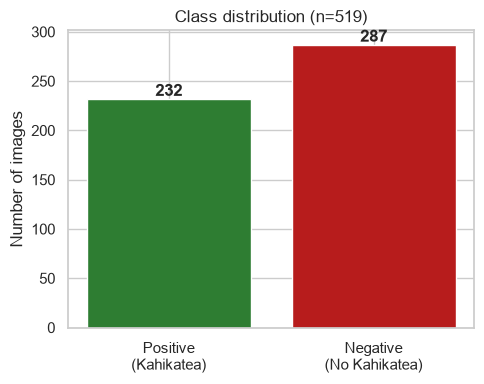

In [51]:
counts = df["class"].value_counts().reindex(["ve_positive", "ve_negative"])
print(counts)
print(f"Positive: {counts['ve_positive']} ({counts['ve_positive']/len(df)*100:.1f}%)")
print(f"Negative: {counts['ve_negative']} ({counts['ve_negative']/len(df)*100:.1f}%)")

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["Positive\n(Kahikatea)", "Negative\n(No Kahikatea)"], counts.values,
               color=[palette["ve_positive"], palette["ve_negative"]])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 3, str(v), ha="center", fontweight="bold")
ax.set_ylabel("Number of images")
ax.set_title(f"Class distribution (n={len(df)})")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_class_distribution.png", dpi=150)
plt.show()


The dataset is close to balanced (55.3% negative vs 44.7% positive, a ratio of roughly 1.24:1). This is a mild imbalance, not severe enough to require aggressive resampling, but it is large enough that a naive model predicting the majority class alone would reach 55.3% accuracy, so accuracy alone should not be used as the primary evaluation metric.

#### Image geometry: dimensions, aspect ratio, 

Checking whether image size is fixed, how aspect ratio behaves, and  importantly, whether dimensions or colour mode are confounded with class label.

            width      height  aspect_ratio  n_channels
count  519.000000  519.000000    519.000000  519.000000
mean   413.876686  276.664740      1.495950    3.015414
std     79.318625   53.022791      0.000321    0.123312
min    368.000000  246.000000      1.493243    3.000000
25%    368.000000  246.000000      1.495935    3.000000
50%    368.000000  246.000000      1.495935    3.000000
75%    442.000000  295.000000      1.495935    3.000000
max    552.000000  369.000000      1.501859    4.000000


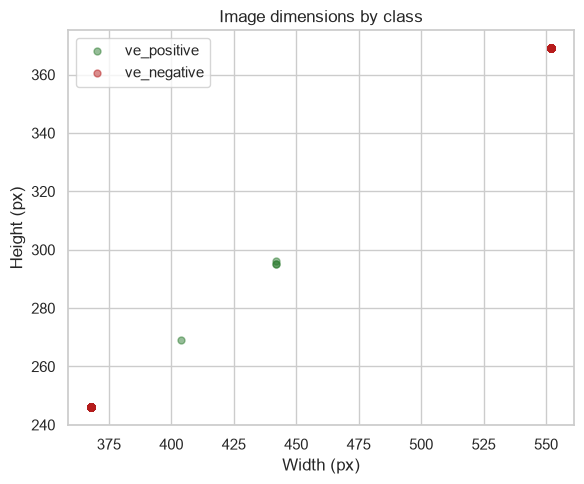

In [52]:
print(df[["width", "height", "aspect_ratio", "n_channels"]].describe())

fig, ax = plt.subplots(figsize=(6, 5))
for cls, c in palette.items():
    sub = df[df["class"] == cls]
    ax.scatter(sub["width"], sub["height"], alpha=0.5, s=25, label=cls, color=c)
ax.set_xlabel("Width (px)"); ax.set_ylabel("Height (px)")
ax.set_title("Image dimensions by class"); ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_dimensions_scatter.png", dpi=150)
plt.show()

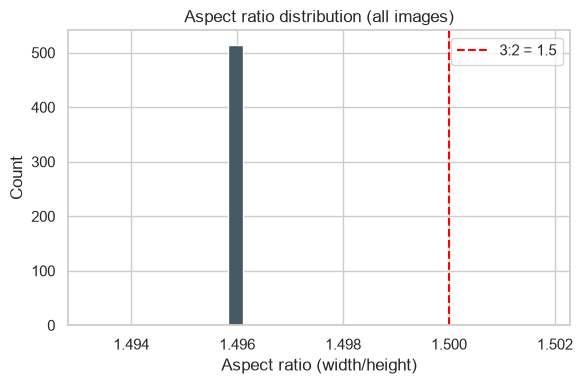

Aspect ratio: mean=1.4960 std=0.0003 min=1.4932 max=1.5019


In [53]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df["aspect_ratio"], bins=30, color="#455a64")
ax.axvline(1.5, color="red", linestyle="--", label="3:2 = 1.5")
ax.set_xlabel("Aspect ratio (width/height)"); ax.set_ylabel("Count")
ax.set_title("Aspect ratio distribution (all images)"); ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_aspect_ratio_hist.png", dpi=150)
plt.show()

print("Aspect ratio: mean=%.4f std=%.4f min=%.4f max=%.4f" %
      (df.aspect_ratio.mean(), df.aspect_ratio.std(), df.aspect_ratio.min(), df.aspect_ratio.max()))


Aspect ratio has a mean of 1.496 and a standard deviation of only 0.0003 (min 1.493, max 1.502), effectively every image is a 3:2 tile. This indicates the images are regular tiles cut from larger orthomosaic aerial surveys at a small number of fixed export resolutions, rather than independently photographed images of varying framing. Because the aspect ratio is constant, resizing to a square or fixed-ratio input will not introduce class-dependent distortion.

res          368x246  404x269  442x295  442x296  552x369
class                                                   
ve_negative      159        0        0        0      128
ve_positive      228        1        2        1        0


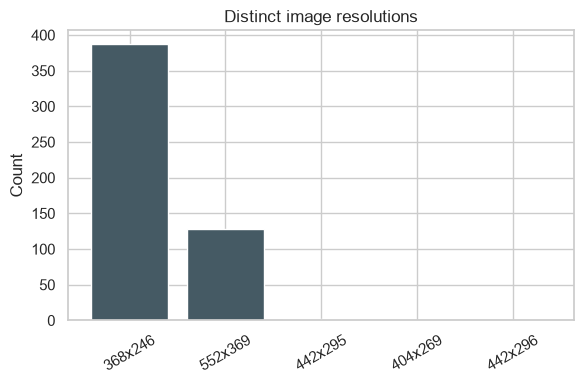

In [54]:
# Resolution vs class cross-tab -- checks for a class/resolution shortcut
df["res"] = df["width"].astype(str) + "x" + df["height"].astype(str)
res_ct = pd.crosstab(df["class"], df["res"])
print(res_ct)

res_counts = df.groupby(["width", "height"]).size().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6, 4))
labels = [f"{w}x{h}" for (w, h) in res_counts.index]
ax.bar(labels, res_counts.values, color="#455a64")
ax.set_ylabel("Count"); ax.set_title("Distinct image resolutions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04_resolutions.png", dpi=150)
plt.show()

Images are not a single fixed size. Five distinct resolutions occur, but 515 of 519 images (99.2%) fall into just two clusters: 368×246 px (387 images, 74.6%) and 552×369 px (128 images, 24.7%); the remaining 4 images are one-off sizes close to these (404×269, 442×295, 442×296).

Critical finding: resolution is confounded with class. Cross-tabulating resolution against class shows that all 128 images at 552×369 px belong exclusively to the negative class, while the dominant 368×246 px size is shared by both classes (228 positive vs 159 negative). This is a serious shortcut-learning / leakage risk: a convolutional network, or even a trivial baseline that reads image metadata, could exploit resolution as a proxy label rather than learning genuine visual cues for Kahikatea presence.

In [ ]:
# Colour mode vs class -- checking for a class/alpha-channel shortcut
print(pd.crosstab(df["class"], df["mode"]))
print(df[df["mode"] == "RGBA"][["class", "filename", "width", "height"]])

mode         RGB  RGBA
class                 
ve_negative  287     0
ve_positive  224     8
           class                             filename  width  height
194  ve_positive  Biospatial_20160702U_2469_04_02.png    368     246
220  ve_positive  Biospatial_20160702U_2479_01_03.png    442     296
226  ve_positive  Biospatial_20170317_U0226_02_03.png    368     246
227  ve_positive  Biospatial_20170317_U0232_02_02.png    368     246
228  ve_positive  Biospatial_20170331_S0755_03_04.png    404     269
229  ve_positive  Biospatial_20170331_U0514_02_02.png    368     246
230  ve_positive  Biospatial_20170331_U0514_03_01.png    442     295
231  ve_positive  Biospatial_20170331_U0515_02_02.png    442     295


Colour channel anomaly: 511 of 519 images (98.5%) are standard 3-channel RGB. The remaining 8 images carry a 4th alpha channel (RGBA) and all 8 belong exclusively to the positive class. Although a small group (3.4% of positives), this is the same class-leakage pattern as the resolution issue: channel count alone weakly predicts class. Both anomalies likely stem from the images being exported from different processing pipelines or GIS/orthomosaic export batches, rather than from any property of the vegetation itself.

#### Brightness, colour and exposure

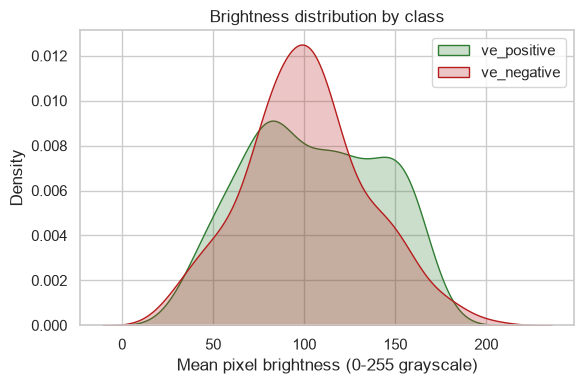

In [56]:
fig, ax = plt.subplots(figsize=(6, 4))
for cls, c in palette.items():
    sns.kdeplot(df.loc[df["class"] == cls, "mean_brightness"], ax=ax, label=cls, color=c, fill=True, alpha=0.25)
ax.set_xlabel("Mean pixel brightness (0-255 grayscale)")
ax.set_title("Brightness distribution by class"); ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05_brightness_by_class.png", dpi=150)
plt.show()

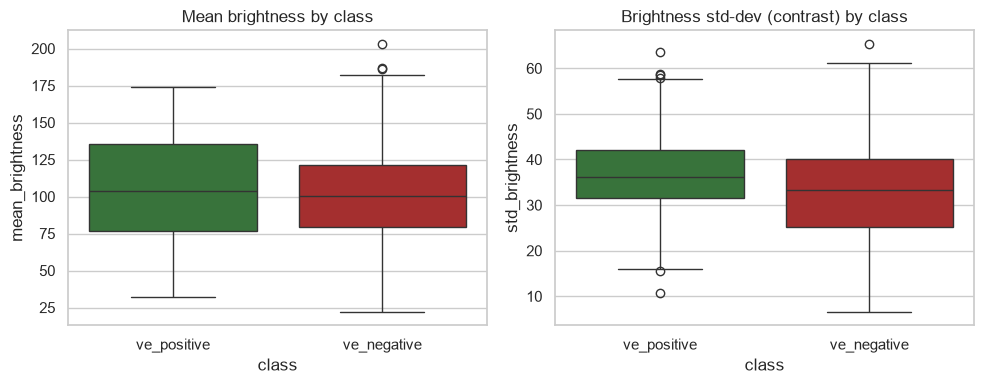

             mean_brightness  std_brightness
class                                       
ve_negative       100.889119       33.038712
ve_positive       104.812203       37.089288


In [57]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=df, x="class", y="mean_brightness", hue="class", legend=False,
            palette=palette, ax=axes[0]); axes[0].set_title("Mean brightness by class")
sns.boxplot(data=df, x="class", y="std_brightness", hue="class", legend=False,
            palette=palette, ax=axes[1]); axes[1].set_title("Brightness std-dev (contrast) by class")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/06_brightness_contrast_box.png", dpi=150)
plt.show()

print(df.groupby("class")[["mean_brightness", "std_brightness"]].mean())


Mean brightness is broadly similar between classes (positive mean 104.8, SD 36.5; negative mean 100.9, SD 33.8, on a 0–255 grayscale scale), with heavy overlap in the distributions and a long right tail in the positive class corresponding to open, sunlit pasture visible around some tree stands. Contrast (brightness standard deviation) is also similar (positive 37.1 vs negative 33.0). The overlap confirms that brightness alone is not a strong discriminator of class consistent with the stated challenge that lighting and shadow variation cuts across both classes rather than separating them.

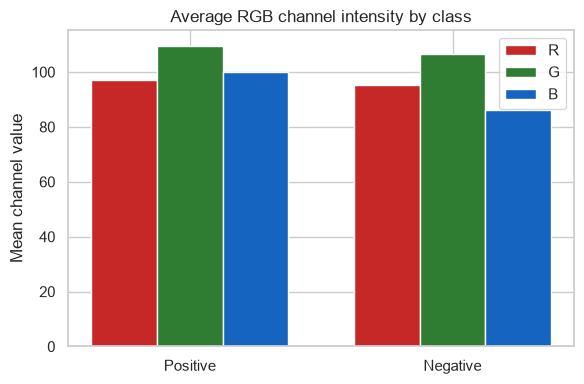

                mean_R      mean_G     mean_B
class                                        
ve_positive  97.239842  109.643397  99.824988
ve_negative  95.217244  106.615822  86.310007


In [58]:
means = df.groupby("class")[["mean_R", "mean_G", "mean_B"]].mean().reindex(["ve_positive", "ve_negative"])
x = np.arange(len(means)); w = 0.25
fig, ax = plt.subplots(figsize=(6, 4))
for i, ch in enumerate(["mean_R", "mean_G", "mean_B"]):
    ax.bar(x + i*w, means[ch], width=w, label=ch.replace("mean_", ""),
           color=["#c62828", "#2e7d32", "#1565c0"][i])
ax.set_xticks(x + w); ax.set_xticklabels(["Positive", "Negative"])
ax.set_ylabel("Mean channel value"); ax.set_title("Average RGB channel intensity by class")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/07_rgb_channel_means.png", dpi=150)
plt.show()
print(means)

The green channel is the brightest channel in both classes, as expected for vegetation and pasture-dominated aerial imagery.

The clearest colour difference is in the blue channel: positive images average a blue value of ~99.7 versus ~86.5 for negative images (roughly 15% relatively higher). This is plausible for the Kahikatea dataset, since many positive tiles include watercourses, wetlands and riparian margins (Kahikatea characteristically grows on former floodplains and swampy ground), which raise the presence of blue water and grey/blue shadow. This is a genuine, content-driven signal, but it is a shortcut candidate too, a model could partly key off 'blue = water = tag as positive' rather than tree canopy texture, so this needs to be considered when checking model explanations 

#### Sharpness / texture and exposure outliers

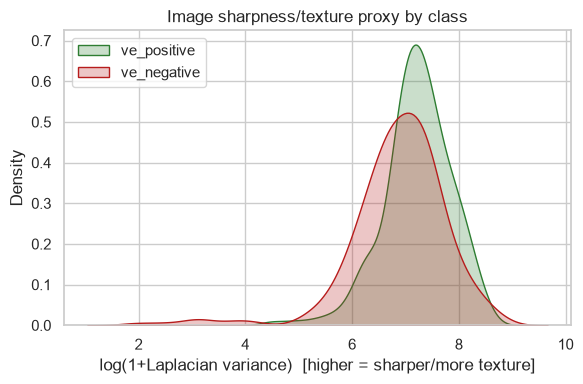

class
ve_negative    1289.598361
ve_positive    1621.755644
Name: laplacian_var, dtype: float64


In [59]:
fig, ax = plt.subplots(figsize=(6, 4))
for cls, c in palette.items():
    sns.kdeplot(np.log1p(df.loc[df["class"] == cls, "laplacian_var"]), ax=ax,
                label=cls, color=c, fill=True, alpha=0.25)
ax.set_xlabel("log(1+Laplacian variance)  [higher = sharper/more texture]")
ax.set_title("Image sharpness/texture proxy by class"); ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/08_sharpness_by_class.png", dpi=150)
plt.show()

print(df.groupby("class")["laplacian_var"].mean())

Positive images have a slightly higher mean Laplacian variance (1622) than negative images (1290), consistent with dense, textured tree canopy producing more high-frequency edge content than smooth pasture or water. The distributions overlap substantially, so this is a weak, not dominant, cue but it means image sharpening/blurring augmentations should be applied conservatively so as not to wash out this texture signal.

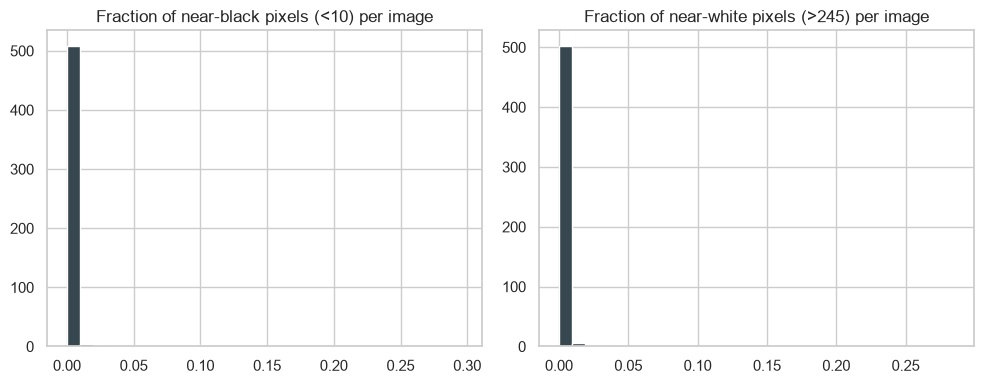

Images with >5% near-black pixels: 3
Images with >5% near-white pixels: 6


In [60]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(df["frac_near_black"], bins=30, color="#37474f")
axes[0].set_title("Fraction of near-black pixels (<10) per image")
axes[1].hist(df["frac_near_white"], bins=30, color="#37474f")
axes[1].set_title("Fraction of near-white pixels (>245) per image")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/09_exposure_extremes.png", dpi=150)
plt.show()

print("Images with >5% near-black pixels:", (df["frac_near_black"] > 0.05).sum())
print("Images with >5% near-white pixels:", (df["frac_near_white"] > 0.05).sum())


The large majority of images have negligible over/under-exposed area, but a small tail of outliers exists: 3 images have more than 5% near-black pixels (deep shadow) and 6 images have more than 5% near-white pixels (sun glint off water/cloud glare, visible in Figure 10, 'Brightest'). 

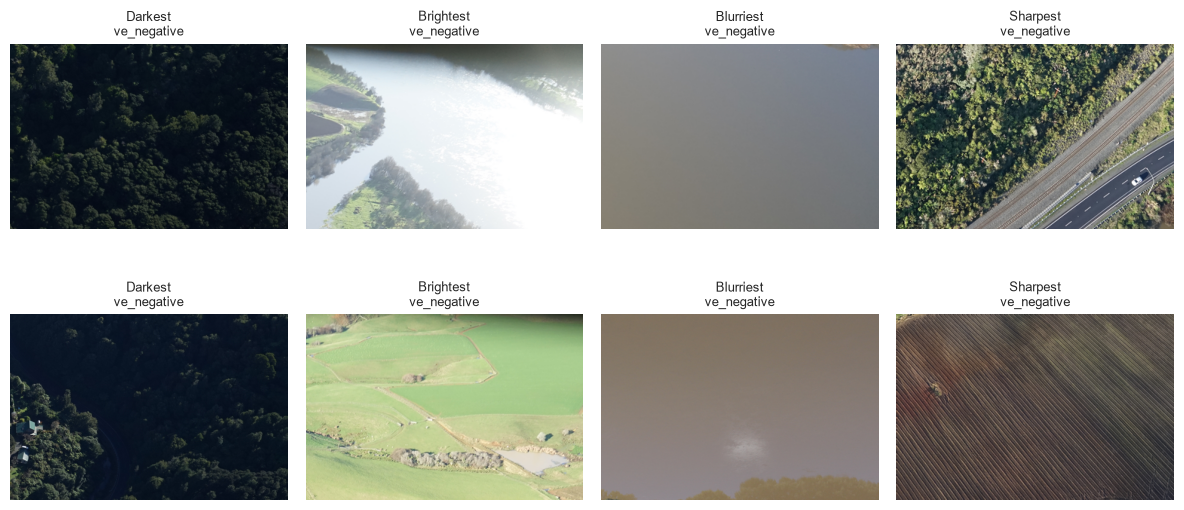

In [61]:
# Darkest / brightest / blurriest / sharpest examples
extremes = {
    "Darkest":   df.nsmallest(2, "mean_brightness"),
    "Brightest": df.nlargest(2, "mean_brightness"),
    "Blurriest": df.nsmallest(2, "laplacian_var"),
    "Sharpest":  df.nlargest(2, "laplacian_var"),
}
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for col, (label, sub) in enumerate(extremes.items()):
    for i, (_, row) in enumerate(sub.iterrows()):
        ax = axes[i, col]
        img = Image.open(row["path"]).convert("RGB")
        ax.imshow(img); ax.set_title(f"{label}\n{row['class']}", fontsize=9); ax.axis("off")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/10_extremes.png", dpi=150)
plt.show()


The lowest-texture images in Figure 10 ('Blurriest') show a hazy, almost featureless frame consistent with motion blur, atmospheric haze, or an out-of-focus capture rather than genuine flat terrain. These are true image-quality defects (not just class variation) and are worth flagging, though at single-digit counts they are not numerous enough to materially bias training if left in, and removing them outright would shrink an already modest dataset.

#### File size

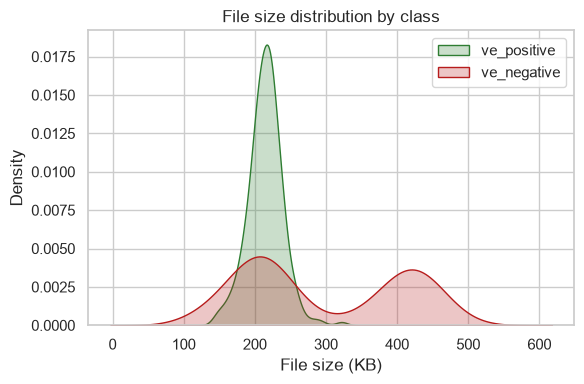

In [62]:
fig, ax = plt.subplots(figsize=(6, 4))
for cls, c in palette.items():
    sns.kdeplot(df.loc[df["class"] == cls, "filesize_kb"], ax=ax, label=cls, color=c, fill=True, alpha=0.25)
ax.set_xlabel("File size (KB)"); ax.set_title("File size distribution by class"); ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/11_filesize_by_class.png", dpi=150)
plt.show()


Negative images are larger on disk on average (296.5 KB vs 214.4 KB), which is largely explained by the resolution confound (larger 552×369 negative-only tiles have more pixels to encode) rather than being an independent quality signal.

#### **Data quality and integrity checks**

#### Duplicate and near-duplicate detection

In [63]:
# Exact duplicates (identical file bytes)

dup_md5 = df[df.duplicated("md5", keep=False)].sort_values("md5")
print("Exact duplicate files:", len(dup_md5))
dup_md5[["class", "filename", "md5"]]


Exact duplicate files: 0


,class,filename,md5


In [64]:
# Near-duplicates via perceptual hash (small Hamming distance = visually similar)

hashes = df["phash"].apply(imagehash.hex_to_hash).tolist()
n = len(hashes)
min_dists = []
for i in range(n):
    best = min(hashes[i] - hashes[j] for j in range(n) if j != i)
    min_dists.append(best)
df["nn_phash_dist"] = min_dists

print(df["nn_phash_dist"].describe())
print("Pairs with distance <= 5 (likely near-duplicates):", (df["nn_phash_dist"] <= 5).sum())
df.sort_values("nn_phash_dist")[["class", "filename", "nn_phash_dist"]].head(10)

count    519.000000
mean      19.198459
std        1.802272
min       12.000000
25%       18.000000
50%       20.000000
75%       20.000000
max       22.000000
Name: nn_phash_dist, dtype: float64
Pairs with distance <= 5 (likely near-duplicates): 0


,class,filename,nn_phash_dist
496,ve_negative,Biospatial_20170317_P1577_03_03.png,12
111,ve_positive,Biospatial_20160702U_2390_01_04.png,12
117,ve_positive,Biospatial_20160702U_2433_01_03.png,12
50,ve_positive,Biospatial_20160702U_2344_01_04.png,12
432,ve_negative,Biospatial_20160702U_2430_01_04.png,14
516,ve_negative,Biospatial_20170317_S1579_01_01.png,14
422,ve_negative,Biospatial_20160702U_2390_02_02.png,14
443,ve_negative,Biospatial_20160702U_2436_04_04.png,14
134,ve_positive,Biospatial_20160702U_2436_01_03.png,14
14,ve_positive,Biospatial_20160702U_1865_01_04.png,14


Every file was hashed (MD5) to check for exact byte-identical duplicates, and a perceptual hash (pHash) was computed for every image to detect near-duplicate or heavily overlapping tiles (e.g. adjacent crops from the same flight pass). No exact duplicates were found. For near-duplicates, the nearest-neighbour pHash Hamming distance across the whole dataset has a minimum of 12, a median of 20, and no pair falls below a distance of 12, well above the conventional near-duplicate threshold of ~5. This indicates the 519 images are visually distinct tiles with no redundant or leaked copies between (or within) the class folders.

#### Filename structure: source tiles, capture dates, spatial correlation

Filenames follow `Biospatial_<date>_<site>_<row>_<col>.png`. Parsing this out
reveals how many images come from the same underlying survey tile, important
for building a leakage-safe train/validation/test split.


In [65]:
pat = re.compile(r"Biospatial_(\d{8})U?_([A-Za-z0-9]+)_(\d+)_(\d+)\.png")

def parse_name(f):
    m = pat.match(f)
    return m.groups() if m else (None, None, None, None)

parsed = df["filename"].apply(parse_name)
df["date"] = parsed.apply(lambda x: x[0])
df["site"] = parsed.apply(lambda x: x[1])
df["row"]  = parsed.apply(lambda x: x[2])
df["col"]  = parsed.apply(lambda x: x[3])

print("Unmatched filenames:", df["date"].isna().sum())
print()
print("Class vs capture date:")
print(pd.crosstab(df["class"], df["date"]))
print()
print("Unique source sites/tiles:", df["site"].nunique(), "for", len(df), "images")

site_class = df.groupby("site")["class"].nunique()
print("Sites containing BOTH classes:", (site_class > 1).sum(), "/", len(site_class))


Unmatched filenames: 0

Class vs capture date:
date         20160603  20160702  20170317  20170331
class                                              
ve_negative       128       127        32         0
ve_positive         0       223         5         4

Unique source sites/tiles: 180 for 519 images
Sites containing BOTH classes: 58 / 180


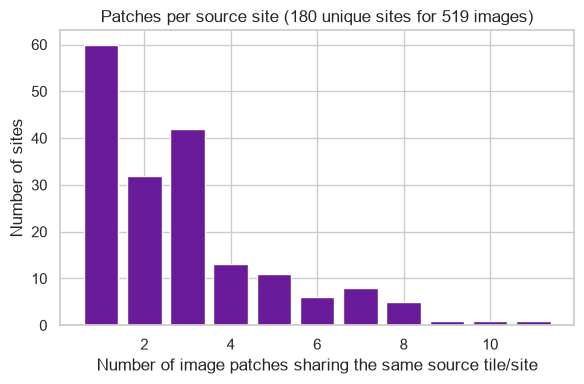

In [66]:
site_counts = df.groupby("site").size().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(site_counts.values, bins=range(1, 13), color="#6a1b9a", align="left", rwidth=0.8)
ax.set_xlabel("Number of image patches sharing the same source tile/site")
ax.set_ylabel("Number of sites")
ax.set_title(f"Patches per source site ({len(site_counts)} unique sites for {len(df)} images)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/12_patches_per_site.png", dpi=150)
plt.show()


Filenames follow a consistent pattern, Biospatial_<capture-date>_<site-ID>_<row>_<col>.png, which reveals that images are patches tiled out of a smaller number of larger source surveys. Parsing this out exposes three related structural issues:

•	Only 4 distinct capture dates are present across the whole dataset (20160603, 20160702, 20170317, 20170331).

•	Capture date is strongly confounded with class: the 20160603 flight contributes 128 images, all negative (and all at the 552×369 resolution identified in §2); the 20170331 flight contributes 4 images, all positive.

•	The 519 images derive from only 180 unique source sites/tiles, and 58 of those 180 sites (32%) contain images from both classes, while many sites contribute multiple neighbouring row/column patches (up to 11 patches from a single site).

This has two practical consequences. First, the date/resolution confound means a model has a spurious shortcut available for identifying a large chunk of the negative class without learning anything about Kahikatea. Second, because many images are spatially adjacent patches cut from the same larger orthomosaic tile, a naive random train/validation/test split risks placing highly correlated neighbouring patches (same lighting, same paddock, same waterway) on both sides of the split, inflating validation performance. 

#### Sample images and extreme cases

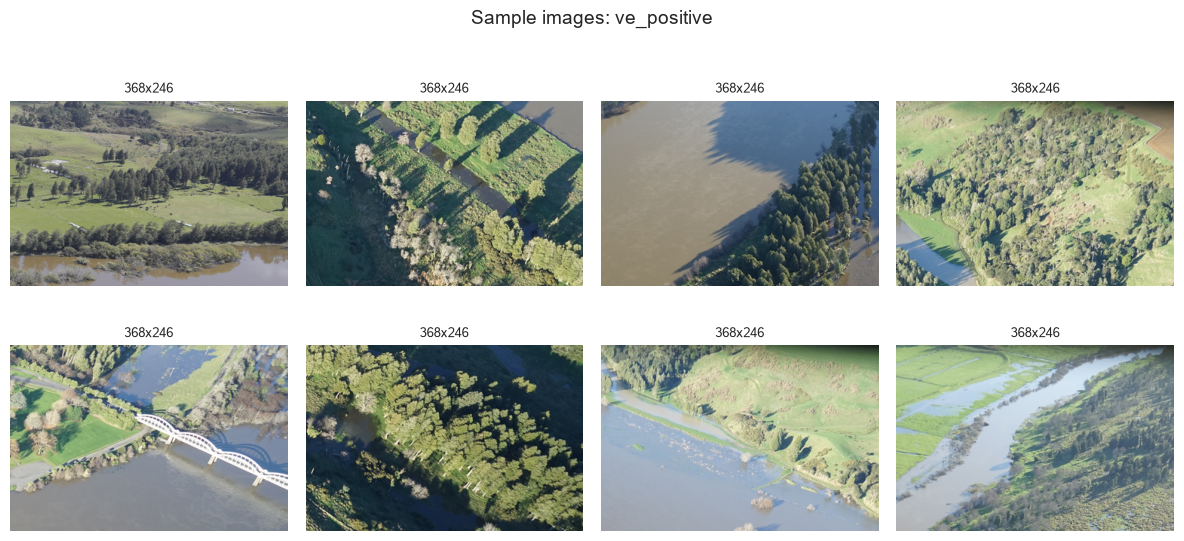

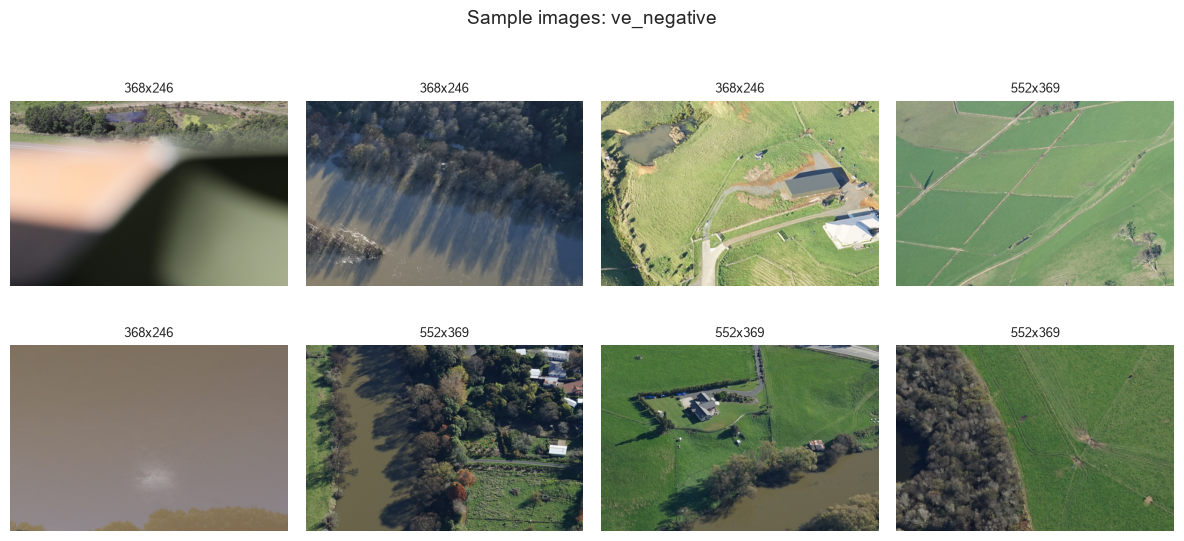

In [67]:
def sample_grid(cls, n=8, seed=1):
    sub = df[df["class"] == cls].sample(n, random_state=seed)
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax, (_, row) in zip(axes.flat, sub.iterrows()):
        img = Image.open(row["path"]).convert("RGB")
        ax.imshow(img); ax.set_title(f"{row['width']}x{row['height']}", fontsize=9); ax.axis("off")
    fig.suptitle(f"Sample images: {cls}", fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/13_samples_{cls}.png", dpi=150)
    plt.show()

sample_grid("ve_positive")
sample_grid("ve_negative")


#### Summary statistics table

In [68]:
summary_cols = ["width", "height", "aspect_ratio", "filesize_kb",
                "mean_brightness", "std_brightness", "laplacian_var"]
summary = df.groupby("class")[summary_cols].agg(["mean", "std", "min", "max"]).round(2)
summary.T

class                 ve_negative  ve_positive
width           mean       450.06       369.11
                std         91.62         8.69
                min        368.00       368.00
                max        552.00       442.00
height          mean       300.86       246.74
                std         61.25         5.78
                min        246.00       246.00
                max        369.00       296.00
aspect_ratio    mean         1.50         1.50
                std          0.00         0.00
                min          1.50         1.49
                max          1.50         1.50
filesize_kb     mean       296.50       214.35
                std        111.77        24.19
                min        105.15       146.63
                max        509.49       321.89
mean_brightness mean       100.89       104.81
                std         33.78        36.51
                min         22.05        31.79
                max        203.15       173.95
std_brightness  mean        33.04        37.09
                std         10.86         8.60
                min          6.57        10.68
                max         65.36        63.66
laplacian_var   mean      1289.60      1621.76
                std       1003.82       953.01
                min          5.93        87.73
                max       6409.91      5038.60

### **Task 2: Data Preparation**

#### Adding the binary label column

`df` already has every column Task 2 needs, it was built once, in Part 1
above (including the `site`/`date` columns parsed from filenames). The only
thing added here is the numeric 0/1 label.


In [69]:
df["label"] = df["class"].map(LABEL_MAP)
print(df["class"].value_counts())
df.head()

class
ve_negative    287
ve_positive    232
Name: count, dtype: int64


,class,filename,path,filesize_kb,md5,format,mode,width,height,aspect_ratio,...,mean_B,frac_near_black,frac_near_white,res,nn_phash_dist,date,site,row,col,label
0,ve_positive,Biospatial_20160702U_1860_01_03.png,../data/kahikatea/data\ve_positive\Biospatial_...,225.226562,e69d585d54e6f5c855e6c1fa847d7bec,PNG,RGB,368,246,1.495935,...,88.068432,0.000000,0.000000,368x246,20,20160702,1860,01,03,1
1,ve_positive,Biospatial_20160702U_1860_02_03.png,../data/kahikatea/data\ve_positive\Biospatial_...,231.900391,f7ea33235121b51f51078b6a5a488c6a,PNG,RGB,368,246,1.495935,...,65.304171,0.000011,0.000000,368x246,20,20160702,1860,02,03,1
2,ve_positive,Biospatial_20160702U_1860_03_03.png,../data/kahikatea/data\ve_positive\Biospatial_...,222.616211,1ef177f8b86a91811c3597eda7dea8a3,PNG,RGB,368,246,1.495935,...,56.055386,0.000110,0.000000,368x246,20,20160702,1860,03,03,1
3,ve_positive,Biospatial_20160702U_1861_01_03.png,../data/kahikatea/data\ve_positive\Biospatial_...,224.642578,abeca5f8beeada77a3ae9184995de5b6,PNG,RGB,368,246,1.495935,...,102.304624,0.000000,0.000453,368x246,18,20160702,1861,01,03,1
4,ve_positive,Biospatial_20160702U_1861_01_04.png,../data/kahikatea/data\ve_positive\Biospatial_...,204.467773,2c5ddeccc4ce019c236fa6a4a5b61a8f,PNG,RGB,368,246,1.495935,...,57.053652,0.010317,0.000000,368x246,20,20160702,1861,01,04,1


#### Standardise colour channels 

**Why this wasn't a Task 1 step:** Task 1 only *measured* that 8 images carry
an alpha channel (RGBA) and that this happens to correlate exclusively with
the positive class, it didn't touch the files. Task 2 fixes it: every image
is forced to 3-channel RGB before it ever reaches the model, so channel
count can no longer act as a label shortcut.

I did this **on the fly** in the loading function rather than overwriting the
source files, so the original dataset stays untouched and reproducible.


In [70]:
def to_rgb(img: Image.Image) -> Image.Image:
    """Force any image (RGB, RGBA, L, P, ...) to 3-channel RGB."""
    if img.mode != "RGB":
        img = img.convert("RGB")
    return img

# Verify: after conversion, every image should report exactly 3 channels
sample_modes = df["mode"].unique().tolist()
print("Modes present before standardisation:", sample_modes)

n_channels_after = []
for _, row in df[df["mode"] != "RGB"].head(5).iterrows():
    img = to_rgb(Image.open(row["path"]))
    n_channels_after.append(len(img.getbands()))
print("Channel count after standardisation (sample of former RGBA files):", n_channels_after)

Modes present before standardisation: ['RGB', 'RGBA']
Channel count after standardisation (sample of former RGBA files): [3, 3, 3, 3, 3]


#### Resize to a fixed input size

**Why this wasn't a Task 1 step:** Task 1 showed the raw dataset has five
different resolutions and that resolution is confounded with class, a model
fed variable-sized inputs (or inputs whose size still varies after a naive
resize) could exploit that confound instead of learning genuine features.
Fixing every image to one identical size removes that shortcut entirely.

**Design choice: letterbox (aspect-preserving) resize, not a direct stretch.**
Every image in the dataset has essentially the same 3:2 aspect ratio (mean
1.496, std 0.0003, from Task 1), so a direct resize to a square would
squash every image by the same amount and wouldn't reintroduce the
resolution confound but it *would* slightly distort tree-crown shapes.
Letterbox padding (resize to fit, then pad with black to a square) preserves
true shapes and is the safer default, at the cost of a thin black border

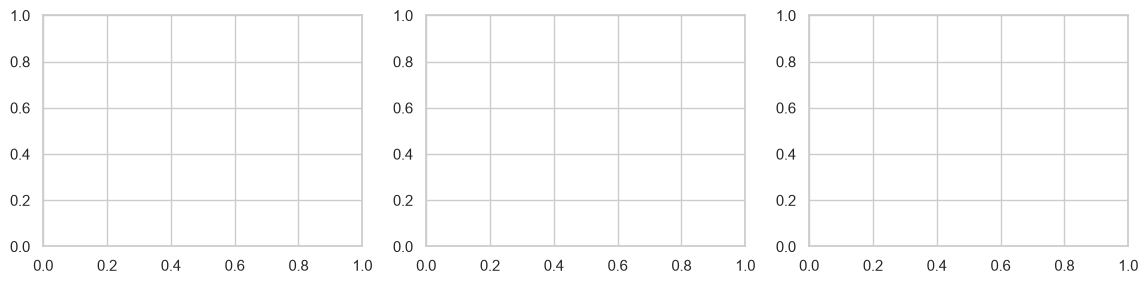

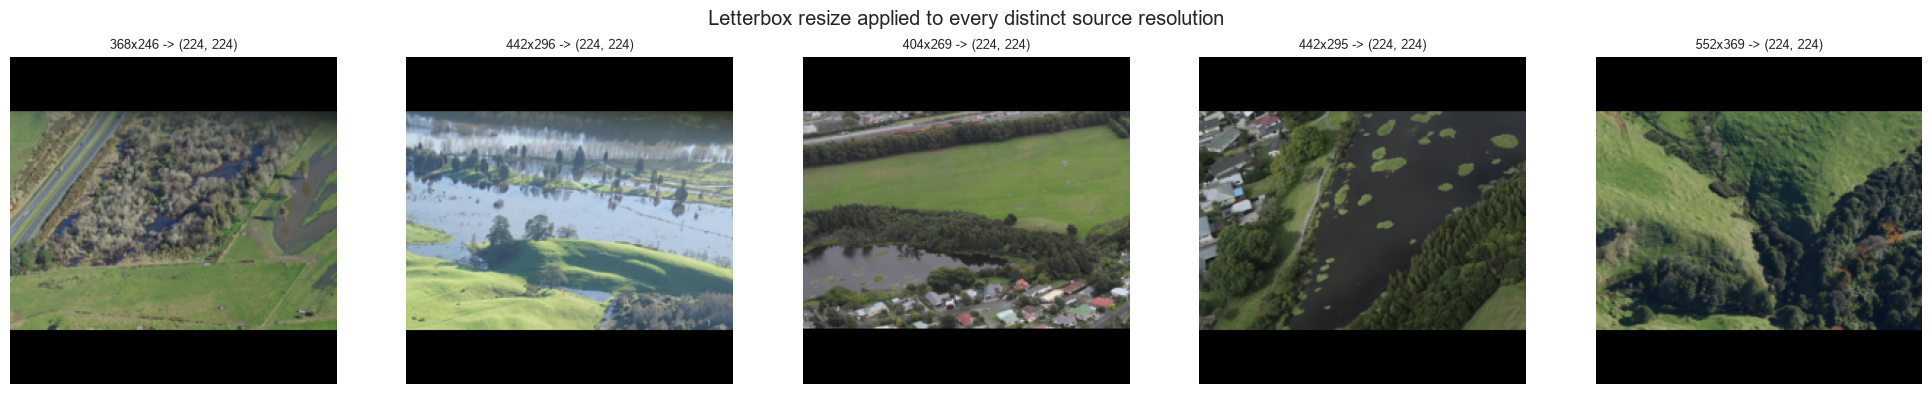

Every output image size: {(224, 224)}


In [71]:
TARGET_SIZE = 224  # square input, matches common pretrained CNN backbones

def letterbox_resize(img: Image.Image, target=TARGET_SIZE, fill=(0, 0, 0)):
    """Resize preserving aspect ratio, then pad to a target x target square."""
    img = to_rgb(img)
    w, h = img.size
    scale = target / max(w, h)
    new_w, new_h = int(round(w * scale)), int(round(h * scale))
    resized = img.resize((new_w, new_h), Image.BILINEAR)

    canvas = Image.new("RGB", (target, target), fill)
    left = (target - new_w) // 2
    top  = (target - new_h) // 2
    canvas.paste(resized, (left, top))
    return canvas

# Sanity check: apply to one image from EACH original resolution cluster
fig, axes = plt.subplots(1, len(df["mode"].unique()) + 1, figsize=(14, 3))
examples = df.drop_duplicates(subset=["width", "height"]).head(5)
fig, axes = plt.subplots(1, len(examples), figsize=(4 * len(examples), 4))
for ax, (_, row) in zip(axes, examples.iterrows()):
    out = letterbox_resize(Image.open(row["path"]))
    ax.imshow(out)
    ax.set_title(f"{row['width']}x{row['height']} -> {out.size}", fontsize=9)
    ax.axis("off")
plt.suptitle("Letterbox resize applied to every distinct source resolution")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/14_letterbox_examples.png", dpi=150)
plt.show()
print("Every output image size:", {letterbox_resize(Image.open(p)).size for p in df["path"].sample(20, random_state=0)})

#### Site-aware, class-stratified train / validation / test split 

**Why this wasn't a Task 1 step:** this is the most important new step. Task 1
found that the 519 images come from only **180 unique source sites**, several
contributing up to 11 neighbouring patches, and that 58 sites contain *both*
classes. A plain random split (e.g. `train_test_split` on individual images)
would very likely place near-identical neighbouring patches from the same
site on both sides of the split, the model would partly be "tested" on
images it has effectively already seen, inflating validation accuracy in a
way that would not hold up on genuinely new aerial surveys.

We use **`StratifiedGroupKFold`**, which guarantees:
- all images from the same `site` end up in the *same* split (no leakage), and
- the class ratio is kept as close as possible to the overall 44.7%/55.3% in
  every split (stratification).

Split sizes target roughly **70% train / 15% validation / 15% test**.

In [72]:
groups = df["site"].values
y = df["label"].values

# Stage 1: carve off the test set (~1/5 of sites) from everything else
sgkf1 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
trainval_idx, test_idx = next(sgkf1.split(df, y, groups))

# Stage 2: split the remainder into train / validation (~4/5 : 1/5 of the remainder)
df_trainval = df.iloc[trainval_idx].reset_index(drop=True)
sgkf2 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, val_idx = next(sgkf2.split(df_trainval, df_trainval["label"], df_trainval["site"]))

df_train = df_trainval.iloc[train_idx].reset_index(drop=True)
df_val   = df_trainval.iloc[val_idx].reset_index(drop=True)
df_test  = df.iloc[test_idx].reset_index(drop=True)

for name, split in [("train", df_train), ("val", df_val), ("test", df_test)]:
    pos = (split["label"] == 1).sum()
    print(f"{name:5s}: {len(split):4d} images  ({pos} pos / {len(split)-pos} neg, "
          f"{pos/len(split)*100:.1f}% positive), {split['site'].nunique()} unique sites")

# --- Leakage check: no site should appear in more than one split ---
train_sites, val_sites, test_sites = set(df_train.site), set(df_val.site), set(df_test.site)
overlap = (train_sites & val_sites) | (train_sites & test_sites) | (val_sites & test_sites)
assert len(overlap) == 0, f"Site leakage detected: {overlap}"
print("\nLeakage check passed: no site appears in more than one split.")

train:  330 images  (148 pos / 182 neg, 44.8% positive), 114 unique sites
val  :   85 images  (38 pos / 47 neg, 44.7% positive), 31 unique sites
test :  104 images  (46 pos / 58 neg, 44.2% positive), 35 unique sites

Leakage check passed: no site appears in more than one split.


#### Pixel scaling and normalisation 

**Why this wasn't a Task 1 step:** Task 1 reported raw brightness/RGB
statistics purely for *analysis* (e.g. the blue-channel shift). Task 2 uses
those same kinds of statistics operationally to normalise pixel values so
the network trains efficiently.

Two steps:
1. **Rescale** every pixel from `[0, 255]` to `[0, 1]`.
2. **Standardise** (zero mean, unit variance) per channel, using statistics
   computed **only from the training split** never from validation/test
   to avoid leaking information about the evaluation data into preprocessing.


In [73]:
def load_and_prepare(path, size=TARGET_SIZE):
    """Full per-image pipeline: open -> RGB -> letterbox resize -> [0,1] float32."""
    img = letterbox_resize(Image.open(path), target=size)
    arr = np.asarray(img, dtype=np.float32) / 255.0
    return arr

# Compute per-channel mean/std from a sample of the TRAINING split only
sample_train = df_train.sample(min(150, len(df_train)), random_state=42)
pixels = np.stack([load_and_prepare(p) for p in sample_train["path"]])
train_mean = pixels.mean(axis=(0, 1, 2))
train_std  = pixels.std(axis=(0, 1, 2))
print("Training-set channel mean (R,G,B):", train_mean.round(4))
print("Training-set channel std  (R,G,B):", train_std.round(4))

def normalise(arr, mean=train_mean, std=train_std):
    return (arr - mean) / std


Training-set channel mean (R,G,B): [0.2537 0.2832 0.2388]
Training-set channel std  (R,G,B): [0.2437 0.2591 0.2158]


#### Class balancing

**Why this wasn't a Task 1 step:** Task 1 only *quantified* the 44.7/55.3
imbalance; Task 2 acts on it. Because the imbalance is mild, full
resampling (oversampling the minority class or undersampling the majority)
isn't warranted, that risks either duplicating too few unique positive
images (overfitting to their exact pixels) or throwing away usable negative
data. Instead we compute **inverse-frequency class weights** from the
training split, to be passed straight into the model's loss function
(e.g. `model.fit(..., class_weight=...)` in Keras).


In [74]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=df_train["label"].values,
)
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}
print("Class weights (0=negative, 1=positive):", class_weight_dict)


Class weights (0=negative, 1=positive): {0: np.float64(0.9065934065934066), 1: np.float64(1.114864864864865)}


#### Data augmentation 

**Why this wasn't a Task 1 step:** augmentation is a training-time operation,
not an analysis step but the *design* of the augmentation pipeline is
directly justified by Task 1's findings:

- **Rotation (0°/90°/180°/270°) and horizontal/vertical flips are safe and
  label-preserving**, because these are nadir (straight-down) aerial images
  with no canonical "up" — flipping or rotating a tile cannot turn a
  Kahikatea stand into something else.

- **Brightness/contrast jitter is applied, but kept moderate**, because
  Task 1 showed real lighting/shadow variation exists naturally in the data
  (so some jitter improves robustness) but it should not be so strong that
  it swamps the genuine blue-channel and texture cues Task 1 identified.

- **No blur augmentation** is applied, because Task 1 showed canopy texture
  (Laplacian variance) is itself a weak positive-class signal; blurring
  would destroy exactly the feature the model needs to learn.

- Augmentation is applied **only to the training split** validation and
  test images are evaluated on their true, unaugmented appearance.

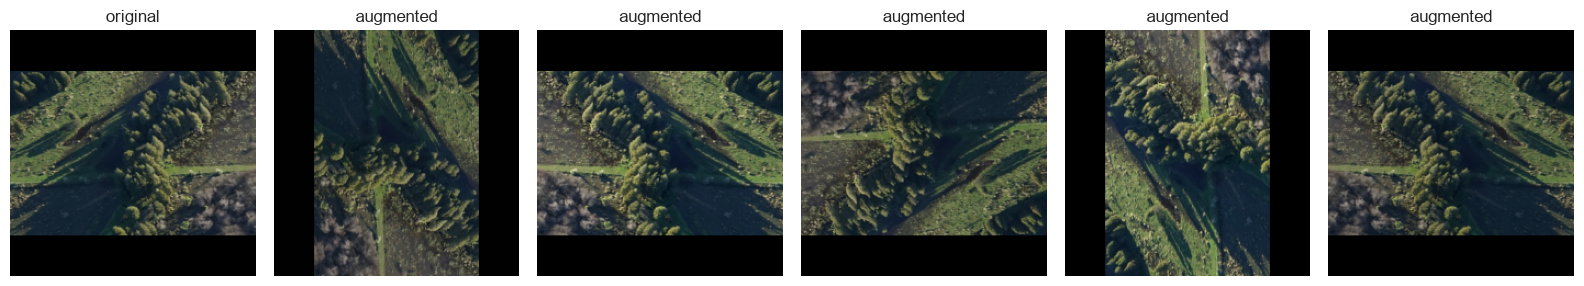

In [75]:
def augment(img: Image.Image, rng: np.random.Generator):
    """Label-preserving augmentation for nadir aerial imagery."""
    # Random rotation by a multiple of 90 degrees (no interpolation artefacts)
    k = rng.integers(0, 4)
    if k:
        img = img.rotate(90 * k, expand=False)

    # Random horizontal / vertical flip
    if rng.random() < 0.5:
        img = img.transpose(Image.FLIP_LEFT_RIGHT)
    if rng.random() < 0.5:
        img = img.transpose(Image.FLIP_TOP_BOTTOM)

    # Mild brightness / contrast jitter (kept conservative, no colour/hue jitter)
    brightness_factor = rng.uniform(0.9, 1.1)
    contrast_factor   = rng.uniform(0.9, 1.1)
    img = ImageEnhance.Brightness(img).enhance(brightness_factor)
    img = ImageEnhance.Contrast(img).enhance(contrast_factor)
    return img

# Visualise: one original training image vs 5 augmented versions of it
rng = np.random.default_rng(7)
example_path = df_train.sample(1, random_state=3)["path"].iloc[0]
original = letterbox_resize(Image.open(example_path))

fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(original); axes[0].set_title("original"); axes[0].axis("off")
for ax in axes[1:]:
    ax.imshow(augment(original.copy(), rng))
    ax.set_title("augmented"); ax.axis("off")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/15_augmentation_examples.png", dpi=150)
plt.show()

#### Handling quality outliers (glare / blur / shadow) flag

**Why this wasn't a Task 1 step:** Task 1 only identified the small tail of
over/under-exposed and low-texture (blurry/hazy) images; it made no changes.
Task 2's decision is to **flag** these rather than delete them: with only
519 images total, discarding data shrinks an already modest training set,
and since Task 1 confirmed these outliers are *not* concentrated in one
class, keeping them helps the model generalise to the imperfect,
real-world flight conditions it will face at inference time. Flagging keeps
the option open for manual review or a future sensitivity analysis.

In [76]:
def quality_flag(path):
    img = np.asarray(Image.open(path).convert("L"))
    frac_black = (img < 10).mean()
    frac_white = (img > 245).mean()
    lap_var = cv2.Laplacian(img, cv2.CV_64F).var()
    return pd.Series({
        "frac_near_black": frac_black,
        "frac_near_white": frac_white,
        "laplacian_var": lap_var,
    })

if not {"frac_near_black", "frac_near_white", "laplacian_var"}.issubset(df.columns):
    qc = df["path"].apply(quality_flag)
    df = pd.concat([df, qc], axis=1)

low_texture_thresh = df["laplacian_var"].quantile(0.02)
df["quality_flag"] = (
    (df["frac_near_black"] > 0.05) |
    (df["frac_near_white"] > 0.05) |
    (df["laplacian_var"] < low_texture_thresh)
)
print("Flagged (kept, not removed):", df["quality_flag"].sum(), "/", len(df), "images")
df[df["quality_flag"]][["class", "filename"]]

Flagged (kept, not removed): 20 / 519 images


,class,filename
126,ve_positive,Biospatial_20160702U_2434_02_04.png
131,ve_positive,Biospatial_20160702U_2435_02_04.png
148,ve_positive,Biospatial_20160702U_2457_02_03.png
169,ve_positive,Biospatial_20160702U_2465_03_03.png
264,ve_negative,Biospatial_20160603U_1216_04_01.png
278,ve_negative,Biospatial_20160603U_1479_04_04.png
285,ve_negative,Biospatial_20160603U_1494_02_03.png
381,ve_negative,Biospatial_20160702U_2340_03_04.png
404,ve_negative,Biospatial_20160702U_2379_04_02.png
405,ve_negative,Biospatial_20160702U_2380_02_02.png


#### Assembling the final preprocessing pipeline

The pieces above are combined into a single function used identically at
train/val/test time, the only difference is that `augment=True` is set for
the training split. This function is framework-agnostic (pure NumPy) so it
can be dropped into a Keras `tf.data.Dataset.from_generator`.


In [77]:
def preprocess_image(path, training=False, rng=None):
    img = Image.open(path)
    img = letterbox_resize(img)                 # channel standardisation + resize
    if training:
        rng = rng or np.random.default_rng()
        img = augment(img, rng)                 # geometric + mild photometric augmentation
    arr = np.asarray(img, dtype=np.float32) / 255.0
    arr = normalise(arr)                         # zero-mean/unit-variance using TRAIN stats
    return arr

def build_split_arrays(split_df, training=False, seed=0):
    rng = np.random.default_rng(seed)
    X = np.stack([preprocess_image(p, training=training, rng=rng) for p in split_df["path"]])
    y = split_df["label"].values.astype(np.float32)
    return X, y

# Demonstrate on a small batch (full-size run left for the modelling notebook)
X_demo, y_demo = build_split_arrays(df_train.sample(8, random_state=1), training=True)
print("Batch shape:", X_demo.shape, "| dtype:", X_demo.dtype,
      "| value range (post-normalisation): [%.2f, %.2f]" % (X_demo.min(), X_demo.max()))
print("Labels:", y_demo)


Batch shape: (8, 224, 224, 3) | dtype: float32 | value range (post-normalisation): [-1.11, 3.06]
Labels: [1. 0. 0. 0. 0. 0. 1. 0.]


#### Final sanity checks

Before moving to model development, confirm the pipeline actually delivers
what Tasks 1–2 required: identical output shape regardless of source
resolution, no group leakage, and a class balance close to the original
ratio in every split.

In [78]:
print("=== Split sizes & class balance ===")
summary = pd.DataFrame({
    name: {
        "n_images": len(split),
        "n_sites": split["site"].nunique(),
        "pct_positive": round((split["label"] == 1).mean() * 100, 1),
    }
    for name, split in [("train", df_train), ("val", df_val), ("test", df_test)]
}).T
print(summary)

print("\n=== Output shape check across all original resolutions ===")
for res, grp in df.groupby(["width", "height"]):
    out_shape = letterbox_resize(Image.open(grp["path"].iloc[0])).size
    print(f"  source {res} -> output {out_shape}")

print("\n=== Site leakage check ===")
print("Overlap between splits:", overlap if overlap else "none")


=== Split sizes & class balance ===
       n_images  n_sites  pct_positive
train     330.0    114.0          44.8
val        85.0     31.0          44.7
test      104.0     35.0          44.2

=== Output shape check across all original resolutions ===
  source (368, 246) -> output (224, 224)
  source (404, 269) -> output (224, 224)
  source (442, 295) -> output (224, 224)
  source (442, 296) -> output (224, 224)
  source (552, 369) -> output (224, 224)

=== Site leakage check ===
Overlap between splits: none
